## TAREA 4           Cristobal Silva 22.158.204-7

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [29]:
rng = np.random.default_rng(seed= 254123) 


## PROBLEMA 1


In [30]:
# Definimos la cantidad de estrellas 
n_estrellas = 100

#Definimos radio, distancias y temperatura efectiva 
radio_estrellas = rng.uniform(0.5,5 ,100)
distancias = rng.uniform(5, 500, 100)
temperatura_efectica = rng.uniform(3000,10000,100)


In [31]:
# Creamos el identificador de las estrellas
ids = [f"estrellas_{i}" for i in range(1, n_estrellas + 1)]


In [32]:
# Creamos un diccionario con los parametros, que luego se generan como tabla
catalogo = {
    'Identificador' :ids,
    'Radios': radio_estrellas,
    'Distancias': distancias,
    'Temperatura efectiva': temperatura_efectica
}

catalogo = pd.DataFrame(catalogo)


In [33]:
# Muestra las primeras 10 muestras 
catalogo.head(10)

,Identificador,Radios,Distancias,Temperatura efectiva
0,estrellas_1,2.830584,313.233795,5622.198970
1,estrellas_2,0.748302,59.574690,8855.715688
2,estrellas_3,3.634068,291.445421,3876.673301
3,estrellas_4,1.236394,188.417621,6236.014475
4,estrellas_5,3.440661,247.377125,7324.671978
5,estrellas_6,0.703223,141.355288,3203.978550
6,estrellas_7,2.473107,17.242570,4620.097712
7,estrellas_8,4.548858,481.725326,9612.904957
8,estrellas_9,3.912878,487.339959,8526.174792
9,estrellas_10,2.761198,18.836290,5114.522321


In [34]:
# Funcion que nos entrega la luminosidad y flujo de cada de una de las 100 estrellas
def calculo_luminosidad_flujo(radio_estrellas,temperatura_efectica,distancias): 
    """
    ----
    Funcion:
    Esta funcion calculara la luminosidad utilizando la ley Stefan-Boltzmann, expresandola en luminosidades solares.
    Ademas utilizando la luminosidad ya calculada, se calculara el flujo de cada una de las estrellas.
    ----
    Parametros:
    r : Los radios que ya tenemos, los convertimos en metros
    d : Las distancias que ya tenemos en parcecs, las pasamos a metros 
    l : Luminosidad esta expresada en watts y la convertimos a luminosidades solares
    Constanste de Boltzmann: 

    ----
    Retorna:
    La funcion retorna la luminosidad y flujo utilizando los parametros antes mencionados.
    ----
    """
    r = radio_estrellas * 6.957*(10**8) # convertimos en metros 
    d = distancias * 3.086 *(10**16) # convertimos de parcecs a metros

    constante_boltzmann = 5.670374419 * (10 ** -8)
    luminosidad_sol = 3.828 * (10**26)

    luminosidad = 4*np.pi*(r**2)*constante_boltzmann*(temperatura_efectica**4)

    flujo = luminosidad / (4*np.pi*(d**2))

    # Convertimos la luminosidad a luminosidades solares
    luminosidad_solar = luminosidad / luminosidad_sol
    return luminosidad_solar, flujo



In [ ]:
# S agrega al catalogo los valores calculados anteriomente, luminosidad y flujo
catalogo['Luminosidad'], catalogo['Flujo observado'] = calculo_luminosidad_flujo(
    catalogo['Radios'], 
    catalogo['Temperatura efectiva'], 
    catalogo['Distancias'])



In [36]:
catalogo.head(10)

,Identificador,Radios,Distancias,Temperatura efectiva,Luminosidad,Flujo observado
0,estrellas_1,2.830584,313.233795,5622.198970,7.212248,2.351276e-12
1,estrellas_2,0.748302,59.574690,8855.715688,3.102717,2.796332e-11
2,estrellas_3,3.634068,291.445421,3876.673301,2.687303,1.011981e-12
3,estrellas_4,1.236394,188.417621,6236.014475,2.082745,1.876564e-12
4,estrellas_5,3.440661,247.377125,7324.671978,30.699427,1.604654e-11
5,estrellas_6,0.703223,141.355288,3203.978550,0.046950,7.515955e-14
6,estrellas_7,2.473107,17.242570,4620.097712,2.510639,2.701161e-10
7,estrellas_8,4.548858,481.725326,9612.904957,159.190432,2.194261e-11
8,estrellas_9,3.912878,487.339959,8526.174792,72.895915,9.817691e-12
9,estrellas_10,2.761198,18.836290,5114.522321,4.700123,4.237295e-10


In [37]:
# Se imprimira la estrella con mayor luminosdidad
indice_max_luminosidad = catalogo['Luminosidad'].idxmax()

estrella_max_lum = catalogo.loc[indice_max_luminosidad]

indice_min_luminosidad = catalogo['Luminosidad'].idxmax()
estrella_min_lum = catalogo.loc[indice_min_luminosidad]

print("Estrella con la mayor luminosidad es :")
print(estrella_max_lum)





Estrella con la mayor luminosidad es :
Identificador           estrellas_36
Radios                      4.646705
Distancias                144.533868
Temperatura efectiva     9980.847338
Luminosidad               193.042791
Flujo observado                  0.0
Name: 35, dtype: object


In [38]:
#Se imprimira la estrella con menor luminosidad 
indice_min_luminosidad = catalogo['Luminosidad'].idxmin()
estrella_min_lum = catalogo.loc[indice_min_luminosidad]

print("Estrella con la menor luminosidad es:")
print(estrella_min_lum)


Estrella con la menor luminosidad es:
Identificador           estrellas_6
Radios                     0.703223
Distancias               141.355288
Temperatura efectiva     3203.97855
Luminosidad                 0.04695
Flujo observado                 0.0
Name: 5, dtype: object


In [39]:
# Se imprime la estrella con el mayor flujo
indice_mayor_flujo = catalogo['Flujo observado'].idxmax()
estrella_max_flujo = catalogo.loc[indice_mayor_flujo]

print("La estrella con mayor flujo es:")
print(estrella_max_flujo)

La estrella con mayor flujo es:
Identificador           estrellas_52
Radios                      4.999724
Distancias                  10.55828
Temperatura efectiva      8839.76161
Luminosidad               137.514317
Flujo observado                  0.0
Name: 51, dtype: object


In [40]:
#Se imprime la estrella con menor flujo 
indice_menor_flujo = catalogo['Flujo observado'].idxmin()
estrella_min_flujo = catalogo.loc[indice_menor_flujo]

print("La estrella con menor flujo es:")
print(estrella_min_flujo)

La estrella con menor flujo es:
Identificador           estrellas_28
Radios                      1.114705
Distancias                347.456998
Temperatura efectiva       3092.7814
Luminosidad                 0.102426
Flujo observado                  0.0
Name: 27, dtype: object


In [41]:
catalogo.head(20)

,Identificador,Radios,Distancias,Temperatura efectiva,Luminosidad,Flujo observado
0,estrellas_1,2.830584,313.233795,5622.198970,7.212248,2.351276e-12
1,estrellas_2,0.748302,59.574690,8855.715688,3.102717,2.796332e-11
2,estrellas_3,3.634068,291.445421,3876.673301,2.687303,1.011981e-12
3,estrellas_4,1.236394,188.417621,6236.014475,2.082745,1.876564e-12
4,estrellas_5,3.440661,247.377125,7324.671978,30.699427,1.604654e-11
5,estrellas_6,0.703223,141.355288,3203.978550,0.046950,7.515955e-14
6,estrellas_7,2.473107,17.242570,4620.097712,2.510639,2.701161e-10
7,estrellas_8,4.548858,481.725326,9612.904957,159.190432,2.194261e-11
8,estrellas_9,3.912878,487.339959,8526.174792,72.895915,9.817691e-12
9,estrellas_10,2.761198,18.836290,5114.522321,4.700123,4.237295e-10


In [42]:
#Creamos la mascara para filtrar los datos 
flujo_limite = 2 * (10**-10)

catalogo['Clasificacion']=np.where(catalogo['Flujo observado']>= flujo_limite, 'Detectada', 'No Detectada')


In [43]:
catalogo.head(-20)

,Identificador,Radios,Distancias,Temperatura efectiva,Luminosidad,Flujo observado,Clasificacion
0,estrellas_1,2.830584,313.233795,5622.198970,7.212248,2.351276e-12,No Detectada
1,estrellas_2,0.748302,59.574690,8855.715688,3.102717,2.796332e-11,No Detectada
2,estrellas_3,3.634068,291.445421,3876.673301,2.687303,1.011981e-12,No Detectada
3,estrellas_4,1.236394,188.417621,6236.014475,2.082745,1.876564e-12,No Detectada
4,estrellas_5,3.440661,247.377125,7324.671978,30.699427,1.604654e-11,No Detectada
...,...,...,...,...,...,...,...
75,estrellas_76,3.615166,267.360198,8170.420455,52.472033,2.348035e-11,No Detectada
76,estrellas_77,4.836841,377.773350,9538.724175,174.493202,3.910985e-11,No Detectada
77,estrellas_78,4.079586,70.397594,3083.155614,1.354901,8.745048e-12,No Detectada
78,estrellas_79,3.167175,336.645967,7237.485179,24.796398,6.998613e-12,No Detectada


In [ ]:
# Se cuentan las estrellas que cumpplen con la condicion
conteo = catalogo['Clasificacion'].value_counts()
print(conteo)

Clasificacion
No Detectada    88
Detectada       12
Name: count, dtype: int64


In [ ]:
# Se cuenta el total de estrellas, las que fueron detectadas y se calcula el porcentaje 
total_estrellas = len(catalogo)
Detectadas = (catalogo['Clasificacion'] == 'Detectada').sum()
porcentaje = (Detectadas / total_estrellas) *100
print(f"El porcentaje de estrellas detectadas es {porcentaje}%")

El porcentaje de estrellas detectadas es 12.0%


In [ ]:
# Agrupamos por la columna de clasificación y calculamos la media de las columnas numéricas
# groupby() :agrupa por categoria en este caso clasificacion
promedios_por_categoria = catalogo.groupby('Clasificacion')[['Flujo observado', 'Distancias', 'Temperatura efectiva']].mean()

print(promedios_por_categoria)

               Flujo observado  Distancias  Temperatura efectiva
Clasificacion                                                   
Detectada         6.430442e-09   38.090208           7626.562162
No Detectada      1.646343e-11  286.124990           6400.529872


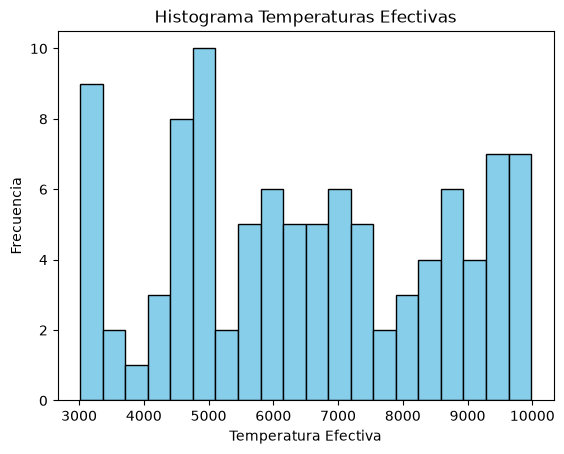

In [ ]:
#Hacemos los histogroma usando matplotlib
#Histogramas de temperaturas

plt.hist(catalogo['Temperatura efectiva'], bins = 20, color = 'skyblue',edgecolor = 'black')
plt.title('Histograma Temperaturas Efectivas')
plt.xlabel('Temperatura Efectiva')
plt.ylabel('Frecuencia')
plt.show()

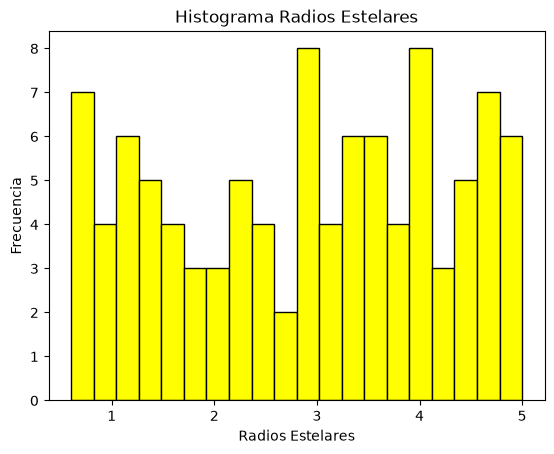

In [50]:
#Histograma radios estelares
plt.hist(catalogo['Radios'], bins = 20, color= 'yellow', edgecolor= 'black')
plt.title('Histograma Radios Estelares')
plt.xlabel('Radios Estelares')
plt.ylabel('Frecuencia')
plt.show()

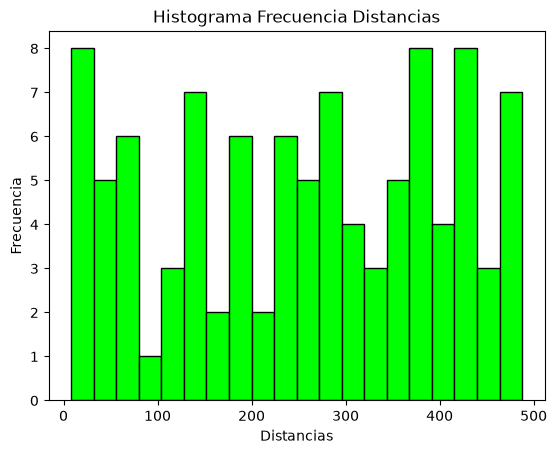

In [59]:
#Histograma distancias
plt.hist(catalogo['Distancias'], bins=20,color='lime',edgecolor= 'black')
plt.title('Histograma Frecuencia Distancias')
plt.xlabel('Distancias')
plt.ylabel('Frecuencia')
plt.show()

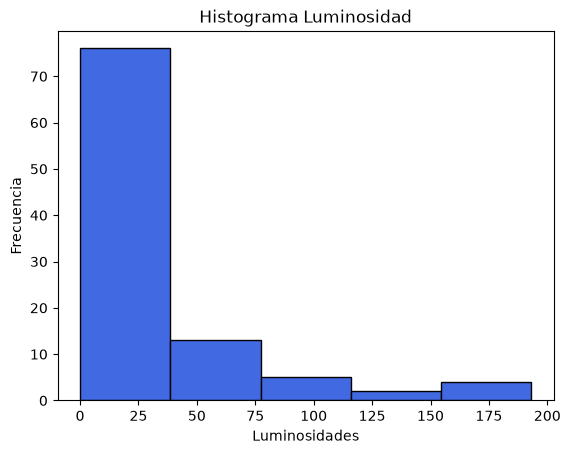

In [66]:
#Histograma Luminosidades
plt.hist(catalogo['Luminosidad'], bins= 5, color='royalblue',edgecolor= 'black')
plt.title('Histograma Luminosidad')
plt.xlabel('Luminosidades')
plt.ylabel('Frecuencia')
plt.show()


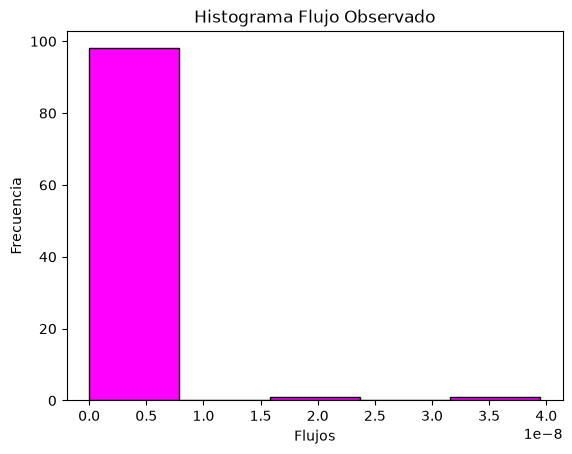

In [72]:
#Histograma Flujo

plt.hist(catalogo['Flujo observado'], bins=5, color= 'magenta', edgecolor= 'black')
plt.title('Histograma Flujo Observado')
plt.xlabel('Flujos')
plt.ylabel('Frecuencia')
plt.show()

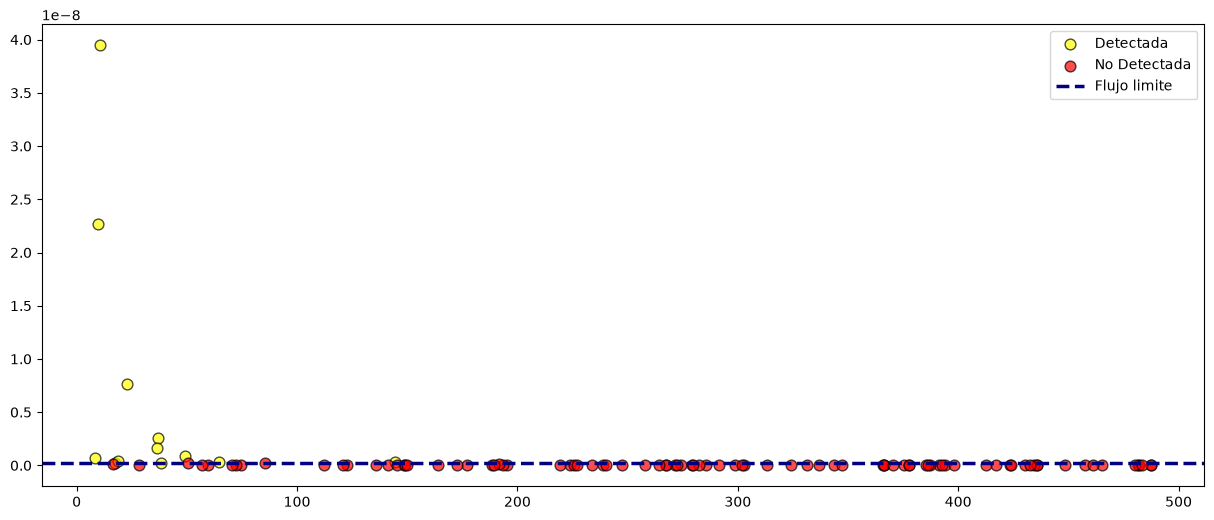

In [ ]:

# Grafico Dispersion del flujo observado sin plt.yscale('log')
plt.figure(figsize=(15,6)) # se define el tamaño de la figura

for clasif, color in [('Detectada', 'yellow'), ('No Detectada','red')]:
    subset = catalogo[catalogo['Clasificacion']== clasif]
    plt.scatter(subset['Distancias'], subset['Flujo observado'], 
                label=clasif, color=color, alpha=0.7, edgecolors='k', s=60) 


#Se establece el flujo limite y se colocara una linea horizontal mediante matplotlib

flujo_limite = 2 * (10**-10)
plt.axhline(y=flujo_limite, color = 'navy', linestyle= '--',linewidth = 2.5, label = 'Flujo limite')
plt.legend()
plt.show()
    

    




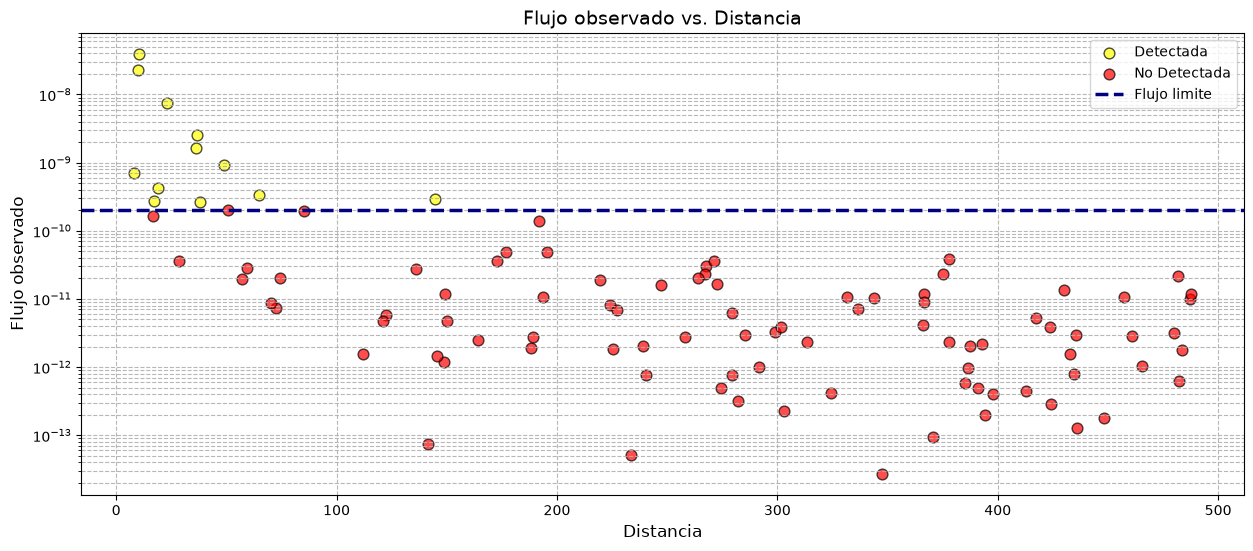

In [ ]:
# Grafico Dispersion del flujo observado
plt.figure(figsize=(15,6)) # se define el tamaño de la figura

for clasif, color in [('Detectada', 'yellow'), ('No Detectada','red')]:
    subset = catalogo[catalogo['Clasificacion']== clasif]
    plt.scatter(subset['Distancias'], subset['Flujo observado'], 
                label=clasif, color=color, alpha=0.7, edgecolors='k', s=60) 


#Se establece el flujo limite y se colocara una linea horizontal mediante matplotlib

flujo_limite = 2 * (10**-10)
plt.axhline(y=flujo_limite, color = 'navy', linestyle= '--',linewidth = 2.5, label = 'Flujo limite')
plt.legend()

plt.yscale('log') # nos cambia la escala con la cual se trabaja en el eje y, permitiendo ver los datos de mejor manera

# Etiquetas y diseño
plt.xlabel('Distancia', fontsize=12)
plt.ylabel('Flujo observado', fontsize=12)
plt.title('Flujo observado vs. Distancia', fontsize=14)
plt.legend()


plt.show()

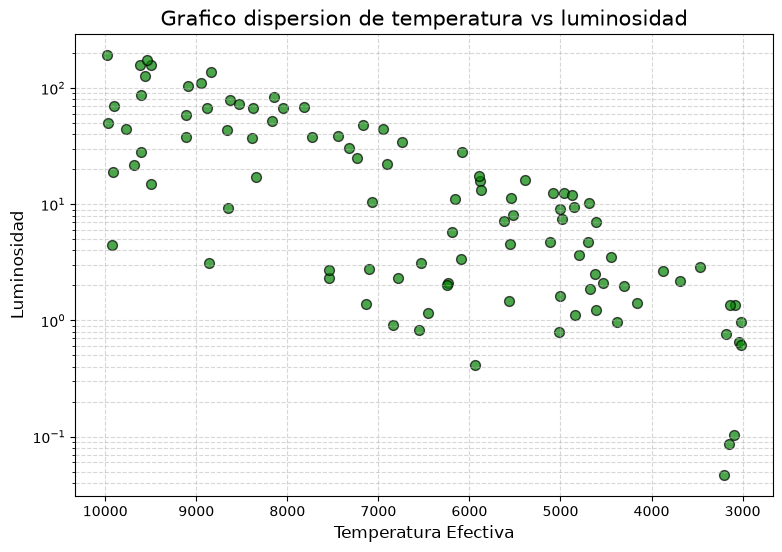

In [ ]:
# Grafica de dispersion entre luminosidad y temperatura
plt.figure(figsize= (9, 6))

plt.scatter(catalogo['Temperatura efectiva'], catalogo['Luminosidad'], color = 'green',edgecolors= 'black', alpha= 0.7, s= 50)

#Transforma la escala a log 
plt.yscale('log')

plt.gca().invert_xaxis()# Invierte de mayor a menor el eje x 

plt.title('Grafico dispersion de temperatura vs luminosidad', fontsize= 15)
plt.xlabel('Temperatura Efectiva', fontsize= 12)
plt.ylabel('Luminosidad', fontsize= 12)
plt.grid(which="both", ls="--", alpha=0.5)


plt.show()

